# Perbandingan Algoritma: RF, SVM, Dempster-Shafer, XGBoost
## Dataset: UNSW-NB15 | 10 Class (Semua Kelas)

**Alur:**
- **Model 1** → Random Forest (independen)
- **Model 2** → SVM (independen)
- **Model 3** → Dempster-Shafer Rule (menggabungkan bukti dari RF + SVM)
- **Model 4** → XGBoost (independen)

**Kelas:** Normal, Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, Worms

**Metrik:** Accuracy, Precision, Recall, F1-Score, Confusion Matrix

---
## 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from xgboost import XGBClassifier

import matplotlib.pyplot as plt
import seaborn as sns

print('✅ Semua library berhasil di-import')

✅ Semua library berhasil di-import


---
## 2. Load Dataset & Cek Records

In [2]:
TRAIN_PATH = '../data/UNSW_NB15_training-set.csv'
TEST_PATH  = '../data/UNSW_NB15_testing-set.csv'

df_train = pd.read_csv(TRAIN_PATH)
df_test  = pd.read_csv(TEST_PATH)

print('=' * 60)
print('          INFORMASI DATASET UNSW-NB15')
print('=' * 60)
print(f'  Training set  : {len(df_train):>8,} records | {df_train.shape[1]} kolom')
print(f'  Testing set   : {len(df_test):>8,} records | {df_test.shape[1]} kolom')
print(f'  Total records : {len(df_train)+len(df_test):>8,} records')
print(f'  Rasio split   : {len(df_train)/(len(df_train)+len(df_test))*100:.0f}% : {len(df_test)/(len(df_train)+len(df_test))*100:.0f}%')
print('=' * 60)

print('\n📊 Distribusi Kelas - Training Set:')
for cls, cnt in df_train['attack_cat'].value_counts().items():
    print(f'  {cls:<18}: {cnt:>6,} records ({cnt/len(df_train)*100:.1f}%)')

print('\n📊 Distribusi Kelas - Testing Set:')
for cls, cnt in df_test['attack_cat'].value_counts().items():
    print(f'  {cls:<18}: {cnt:>6,} records ({cnt/len(df_test)*100:.1f}%)')

          INFORMASI DATASET UNSW-NB15
  Training set  :  175,341 records | 45 kolom
  Testing set   :   82,332 records | 45 kolom
  Total records :  257,673 records
  Rasio split   : 68% : 32%

📊 Distribusi Kelas - Training Set:
  Normal            : 56,000 records (31.9%)
  Generic           : 40,000 records (22.8%)
  Exploits          : 33,393 records (19.0%)
  Fuzzers           : 18,184 records (10.4%)
  DoS               : 12,264 records (7.0%)
  Reconnaissance    : 10,491 records (6.0%)
  Analysis          :  2,000 records (1.1%)
  Backdoor          :  1,746 records (1.0%)
  Shellcode         :  1,133 records (0.6%)
  Worms             :    130 records (0.1%)

📊 Distribusi Kelas - Testing Set:
  Normal            : 37,000 records (44.9%)
  Generic           : 18,871 records (22.9%)
  Exploits          : 11,132 records (13.5%)
  Fuzzers           :  6,062 records (7.4%)
  DoS               :  4,089 records (5.0%)
  Reconnaissance    :  3,496 records (4.2%)
  Analysis          :    

---
## 2. Preprocessing: cek missing/duplikat

In [3]:
print('=' * 60)
print('          PREPROCESSING: DATA QUALITY CHECK')
print('=' * 60)

# ---- Cek missing value ----
missing_train = df_train.isnull().sum().sum()
missing_test  = df_test.isnull().sum().sum()
print(f'  Missing values (train) : {missing_train}')
print(f'  Missing values (test)  : {missing_test}')

# ---- Cek duplikat ----
dup_train = df_train.duplicated().sum()
dup_test  = df_test.duplicated().sum()
print(f'  Duplicate rows (train) : {dup_train}')
print(f'  Duplicate rows (test)  : {dup_test}')

# ---- Hapus duplikat kalau ada ----
if dup_train > 0:
    df_train = df_train.drop_duplicates().reset_index(drop=True)
    print(f'  -> {dup_train} baris duplikat pada training set telah dihapus')
if dup_test > 0:
    df_test = df_test.drop_duplicates().reset_index(drop=True)
    print(f'  -> {dup_test} baris duplikat pada testing set telah dihapus')

print('=' * 60)
print('✅ Preprocessing (data quality check) selesai')
print('=' * 60)

          PREPROCESSING: DATA QUALITY CHECK
  Missing values (train) : 0
  Missing values (test)  : 0
  Duplicate rows (train) : 0
  Duplicate rows (test)  : 0
✅ Preprocessing (data quality check) selesai


---
## 3. Transformation: Encoding & Scaling

In [4]:
DROP_COLS = ['id', 'attack_cat', 'label']
CAT_COLS  = ['proto', 'service', 'state']

# ---- Encode kolom kategorik ----
le = LabelEncoder()
for col in CAT_COLS:
    if col in df_train.columns:
        combined = pd.concat([df_train[col], df_test[col]])
        le.fit(combined)
        df_train[col] = le.transform(df_train[col])
        df_test[col]  = le.transform(df_test[col])

# ---- Pisah fitur & label ----
existing_drop = [c for c in DROP_COLS if c in df_train.columns]
X_train = df_train.drop(columns=existing_drop)
X_test  = df_test.drop(columns=existing_drop)

# ---- Encode label target (semua 10 kelas) ----
le_target = LabelEncoder()
le_target.fit(pd.concat([df_train['attack_cat'], df_test['attack_cat']]))
y_train = le_target.transform(df_train['attack_cat'])
y_test  = le_target.transform(df_test['attack_cat'])

CLASS_NAMES = le_target.classes_
N_CLASSES   = len(CLASS_NAMES)

print(f'✅ Preprocessing selesai')
print(f'   Jumlah fitur  : {X_train.shape[1]}')
print(f'   Jumlah kelas  : {N_CLASSES}')
print(f'   Kelas         : {list(CLASS_NAMES)}')
print(f'   Mapping kelas : {dict(zip(CLASS_NAMES, le_target.transform(CLASS_NAMES)))}')

# ---- Scaling (wajib untuk SVM) ----
scaler = StandardScaler()   
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)
print(f'   Scaling       : StandardScaler (untuk SVM)')

✅ Preprocessing selesai
   Jumlah fitur  : 42
   Jumlah kelas  : 10
   Kelas         : ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']
   Mapping kelas : {'Analysis': np.int64(0), 'Backdoor': np.int64(1), 'DoS': np.int64(2), 'Exploits': np.int64(3), 'Fuzzers': np.int64(4), 'Generic': np.int64(5), 'Normal': np.int64(6), 'Reconnaissance': np.int64(7), 'Shellcode': np.int64(8), 'Worms': np.int64(9)}
   Scaling       : StandardScaler (untuk SVM)


---
## 4. Model 1 — Random Forest

In [5]:
print('🌲 Training Random Forest...')

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

t0 = time.time()
rf_model.fit(X_train, y_train)
rf_train_time = time.time() - t0

t0 = time.time()
y_pred_rf  = rf_model.predict(X_test)
rf_prob    = rf_model.predict_proba(X_test)   # untuk Dempster-Shafer
rf_pred_time = time.time() - t0

rf_acc  = accuracy_score(y_test, y_pred_rf)
rf_prec = precision_score(y_test, y_pred_rf, average='weighted', zero_division=0)
rf_rec  = recall_score(y_test, y_pred_rf, average='weighted', zero_division=0)
rf_f1   = f1_score(y_test, y_pred_rf, average='weighted', zero_division=0)

print(f'\n✅ Random Forest selesai!')
print(f'   Waktu training  : {rf_train_time:.2f} detik')
print(f'   Waktu prediksi  : {rf_pred_time:.4f} detik')
print(f'\n📊 Hasil Evaluasi:')
print(f'   Accuracy  : {rf_acc*100:.2f}%')
print(f'   Precision : {rf_prec:.4f}')
print(f'   Recall    : {rf_rec:.4f}')
print(f'   F1-Score  : {rf_f1:.4f}')
print(f'\n📋 Classification Report:')
print(classification_report(y_test, y_pred_rf, target_names=CLASS_NAMES))

🌲 Training Random Forest...



✅ Random Forest selesai!
   Waktu training  : 5.78 detik
   Waktu prediksi  : 0.6334 detik

📊 Hasil Evaluasi:
   Accuracy  : 75.43%
   Precision : 0.8411
   Recall    : 0.7543
   F1-Score  : 0.7780

📋 Classification Report:
                precision    recall  f1-score   support

      Analysis       0.00      0.01      0.01       677
      Backdoor       0.02      0.09      0.03       583
           DoS       0.61      0.12      0.20      4089
      Exploits       0.63      0.78      0.69     11132
       Fuzzers       0.29      0.59      0.39      6062
       Generic       1.00      0.97      0.98     18871
        Normal       0.97      0.75      0.85     37000
Reconnaissance       0.93      0.80      0.86      3496
     Shellcode       0.34      0.70      0.46       378
         Worms       0.44      0.16      0.23        44

      accuracy                           0.75     82332
     macro avg       0.52      0.50      0.47     82332
  weighted avg       0.84      0.75      0.78

---
## 5. Model 2 — SVM

In [6]:
print('⚙️  Training SVM (RBF Kernel)...')
print('   (Proses ini membutuhkan waktu lebih lama pada dataset besar)')

svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,      # wajib True agar menghasilkan probabilitas untuk DST
    random_state=42,
    decision_function_shape='ovr'
)

t0 = time.time()
svm_model.fit(X_train_scaled, y_train)
svm_train_time = time.time() - t0

t0 = time.time()
y_pred_svm  = svm_model.predict(X_test_scaled)
svm_prob    = svm_model.predict_proba(X_test_scaled)  # untuk Dempster-Shafer
svm_pred_time = time.time() - t0

svm_acc  = accuracy_score(y_test, y_pred_svm)
svm_prec = precision_score(y_test, y_pred_svm, average='weighted', zero_division=0)
svm_rec  = recall_score(y_test, y_pred_svm, average='weighted', zero_division=0)
svm_f1   = f1_score(y_test, y_pred_svm, average='weighted', zero_division=0)

print(f'\n✅ SVM selesai!')
print(f'   Waktu training  : {svm_train_time:.2f} detik')
print(f'   Waktu prediksi  : {svm_pred_time:.4f} detik')
print(f'\n📊 Hasil Evaluasi:')
print(f'   Accuracy  : {svm_acc*100:.2f}%')
print(f'   Precision : {svm_prec:.4f}')
print(f'   Recall    : {svm_rec:.4f}')
print(f'   F1-Score  : {svm_f1:.4f}')
print(f'\n📋 Classification Report:')
print(classification_report(y_test, y_pred_svm, target_names=CLASS_NAMES))

⚙️  Training SVM (RBF Kernel)...
   (Proses ini membutuhkan waktu lebih lama pada dataset besar)

✅ SVM selesai!
   Waktu training  : 5077.25 detik
   Waktu prediksi  : 1022.0639 detik

📊 Hasil Evaluasi:
   Accuracy  : 70.51%
   Precision : 0.8157
   Recall    : 0.7051
   F1-Score  : 0.7130

📋 Classification Report:
                precision    recall  f1-score   support

      Analysis       0.00      0.00      0.00       677
      Backdoor       0.00      0.00      0.00       583
           DoS       0.69      0.01      0.03      4089
      Exploits       0.54      0.87      0.66     11132
       Fuzzers       0.26      0.73      0.38      6062
       Generic       1.00      0.96      0.98     18871
        Normal       0.98      0.63      0.77     37000
Reconnaissance       0.52      0.69      0.59      3496
     Shellcode       0.00      0.00      0.00       378
         Worms       1.00      0.02      0.04        44

      accuracy                           0.71     82332
     mac

---
## 6. Model 3 — Dempster-Shafer Theory (Kombinasi RF + SVM)

**Cara kerja:**
1. RF dan SVM menghasilkan probabilitas prediksi per kelas → menjadi *mass function* (m₁ dan m₂)
2. Dempster's Rule of Combination menggabungkan m₁ dan m₂ menjadi satu keyakinan gabungan
3. Kelas dengan keyakinan tertinggi dipilih sebagai prediksi akhir

**Formula:** `m₁₂(A) = Σ m₁(B) × m₂(C) / (1 - K)` di mana K adalah faktor konflik antar bukti

In [7]:
def dempster_combination(m1, m2):
    """
    Dempster's Rule of Combination untuk multi-class.
    m1, m2 : array probabilitas per kelas (shape: [n_samples, n_classes])
    Return  : array keyakinan gabungan (shape: [n_samples, n_classes])
    """
    n_samples, n_classes = m1.shape
    combined  = np.zeros_like(m1)
    K_values  = np.zeros(n_samples)

    for i in range(n_samples):
        # Hitung faktor konflik K
        K = 0.0
        for c1 in range(n_classes):
            for c2 in range(n_classes):
                if c1 != c2:
                    K += m1[i, c1] * m2[i, c2]
        K_values[i] = K

        norm = 1.0 - K
        if norm < 1e-10:
            # Konflik total → pakai rata-rata sebagai fallback
            combined[i] = (m1[i] + m2[i]) / 2.0
        else:
            for c in range(n_classes):
                combined[i, c] = (m1[i, c] * m2[i, c]) / norm

    return combined, K_values


print('🔗 Menjalankan Dempster-Shafer Rule of Combination...')
print('   Sumber bukti 1 : Random Forest')
print('   Sumber bukti 2 : SVM')

t0 = time.time()
dst_belief, K_values = dempster_combination(rf_prob, svm_prob)
y_pred_dst   = np.argmax(dst_belief, axis=1)
dst_pred_time = time.time() - t0

dst_acc  = accuracy_score(y_test, y_pred_dst)
dst_prec = precision_score(y_test, y_pred_dst, average='weighted', zero_division=0)
dst_rec  = recall_score(y_test, y_pred_dst, average='weighted', zero_division=0)
dst_f1   = f1_score(y_test, y_pred_dst, average='weighted', zero_division=0)

print(f'\n✅ Dempster-Shafer selesai!')
print(f'   Waktu kombinasi       : {dst_pred_time:.4f} detik')
print(f'   Rata-rata konflik (K) : {np.mean(K_values):.4f}')
print(f'   (K mendekati 0 = RF & SVM sering setuju, mendekati 1 = banyak konflik)')
print(f'\n📊 Hasil Evaluasi:')
print(f'   Accuracy  : {dst_acc*100:.2f}%')
print(f'   Precision : {dst_prec:.4f}')
print(f'   Recall    : {dst_rec:.4f}')
print(f'   F1-Score  : {dst_f1:.4f}')
print(f'\n📋 Classification Report:')
print(classification_report(y_test, y_pred_dst, target_names=CLASS_NAMES))

🔗 Menjalankan Dempster-Shafer Rule of Combination...
   Sumber bukti 1 : Random Forest
   Sumber bukti 2 : SVM

✅ Dempster-Shafer selesai!
   Waktu kombinasi       : 2.2682 detik
   Rata-rata konflik (K) : 0.3352
   (K mendekati 0 = RF & SVM sering setuju, mendekati 1 = banyak konflik)

📊 Hasil Evaluasi:
   Accuracy  : 75.42%
   Precision : 0.8309
   Recall    : 0.7542
   F1-Score  : 0.7647

📋 Classification Report:
                precision    recall  f1-score   support

      Analysis       0.00      0.00      0.00       677
      Backdoor       0.03      0.02      0.02       583
           DoS       0.68      0.05      0.09      4089
      Exploits       0.59      0.85      0.70     11132
       Fuzzers       0.27      0.62      0.38      6062
       Generic       1.00      0.96      0.98     18871
        Normal       0.95      0.75      0.84     37000
Reconnaissance       0.91      0.74      0.82      3496
     Shellcode       0.53      0.49      0.51       378
         Worms     

---
## 7. Model 4 — XGBoost

In [8]:
print('⚡ Training XGBoost...')

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective='multi:softprob',
    num_class=N_CLASSES,
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

t0 = time.time()
xgb_model.fit(X_train, y_train)
xgb_train_time = time.time() - t0

t0 = time.time()
y_pred_xgb    = xgb_model.predict(X_test)
xgb_pred_time = time.time() - t0

xgb_acc  = accuracy_score(y_test, y_pred_xgb)
xgb_prec = precision_score(y_test, y_pred_xgb, average='weighted', zero_division=0)
xgb_rec  = recall_score(y_test, y_pred_xgb, average='weighted', zero_division=0)
xgb_f1   = f1_score(y_test, y_pred_xgb, average='weighted', zero_division=0)

print(f'\n✅ XGBoost selesai!')
print(f'   Waktu training  : {xgb_train_time:.2f} detik')
print(f'   Waktu prediksi  : {xgb_pred_time:.4f} detik')
print(f'\n📊 Hasil Evaluasi:')
print(f'   Accuracy  : {xgb_acc*100:.2f}%')
print(f'   Precision : {xgb_prec:.4f}')
print(f'   Recall    : {xgb_rec:.4f}')
print(f'   F1-Score  : {xgb_f1:.4f}')
print(f'\n📋 Classification Report:')
print(classification_report(y_test, y_pred_xgb, target_names=CLASS_NAMES))

⚡ Training XGBoost...

✅ XGBoost selesai!
   Waktu training  : 6.36 detik
   Waktu prediksi  : 0.2123 detik

📊 Hasil Evaluasi:
   Accuracy  : 76.55%
   Precision : 0.8330
   Recall    : 0.7655
   F1-Score  : 0.7778

📋 Classification Report:
                precision    recall  f1-score   support

      Analysis       0.06      0.07      0.06       677
      Backdoor       0.04      0.11      0.06       583
           DoS       0.51      0.07      0.13      4089
      Exploits       0.59      0.86      0.70     11132
       Fuzzers       0.31      0.61      0.41      6062
       Generic       1.00      0.97      0.98     18871
        Normal       0.97      0.76      0.85     37000
Reconnaissance       0.93      0.81      0.86      3496
     Shellcode       0.32      0.75      0.45       378
         Worms       0.60      0.34      0.43        44

      accuracy                           0.77     82332
     macro avg       0.53      0.54      0.49     82332
  weighted avg       0.83    

---
## 8. Tabel Perbandingan 4 Model

In [9]:
all_scores = {
    'Random Forest'   : [rf_acc,  rf_prec,  rf_rec,  rf_f1],
    'SVM'             : [svm_acc, svm_prec, svm_rec, svm_f1],
    'Dempster-Shafer' : [dst_acc, dst_prec, dst_rec, dst_f1],
    'XGBoost'         : [xgb_acc, xgb_prec, xgb_rec, xgb_f1],
}
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

results = pd.DataFrame(all_scores, index=metric_names).T
results.columns = metric_names
results['Training Time (s)'] = [
    f'{rf_train_time:.2f}',
    f'{svm_train_time:.2f}',
    '-',
    f'{xgb_train_time:.2f}'
]

print('=' * 80)
print('              TABEL PERBANDINGAN 4 ALGORITMA')
print('=' * 80)
print(f"  {'Algoritma':<20} | {'Accuracy':>9} | {'Precision':>9} | {'Recall':>9} | {'F1-Score':>9} | {'Train Time':>10}")
print('-' * 80)
for name, row in results.iterrows():
    print(f"  {name:<20} | {row['Accuracy']:>9.4f} | {row['Precision']:>9.4f} | {row['Recall']:>9.4f} | {row['F1-Score']:>9.4f} | {row['Training Time (s)']:>10}")
print('=' * 80)

print('\n🏆 PEMENANG PER METRIK:')
for i, metric in enumerate(metric_names):
    best = max(all_scores, key=lambda k: all_scores[k][i])
    print(f'   {metric:<12}: {best} ({all_scores[best][i]:.4f})')

train_times = {'Random Forest': rf_train_time, 'SVM': svm_train_time, 'XGBoost': xgb_train_time}
fastest = min(train_times, key=train_times.get)
print(f'\n⚡ TRAINING TERCEPAT   : {fastest} ({train_times[fastest]:.2f}s)')

              TABEL PERBANDINGAN 4 ALGORITMA
  Algoritma            |  Accuracy | Precision |    Recall |  F1-Score | Train Time
--------------------------------------------------------------------------------
  Random Forest        |    0.7543 |    0.8411 |    0.7543 |    0.7780 |       5.78
  SVM                  |    0.7051 |    0.8157 |    0.7051 |    0.7130 |    5077.25
  Dempster-Shafer      |    0.7542 |    0.8309 |    0.7542 |    0.7647 |          -
  XGBoost              |    0.7655 |    0.8330 |    0.7655 |    0.7778 |       6.36

🏆 PEMENANG PER METRIK:
   Accuracy    : XGBoost (0.7655)
   Precision   : Random Forest (0.8411)
   Recall      : XGBoost (0.7655)
   F1-Score    : Random Forest (0.7780)

⚡ TRAINING TERCEPAT   : Random Forest (5.78s)


---
## 9. Visualisasi — Confusion Matrix (4 Model)

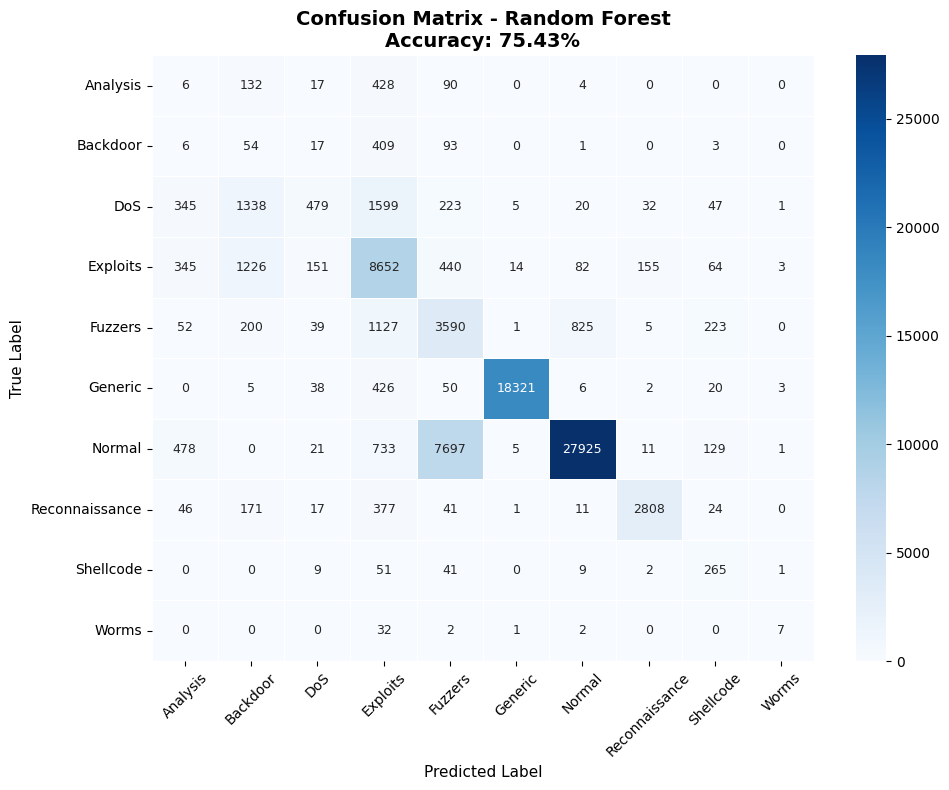

✅ confusion_matrix_rf.png berhasil disimpan


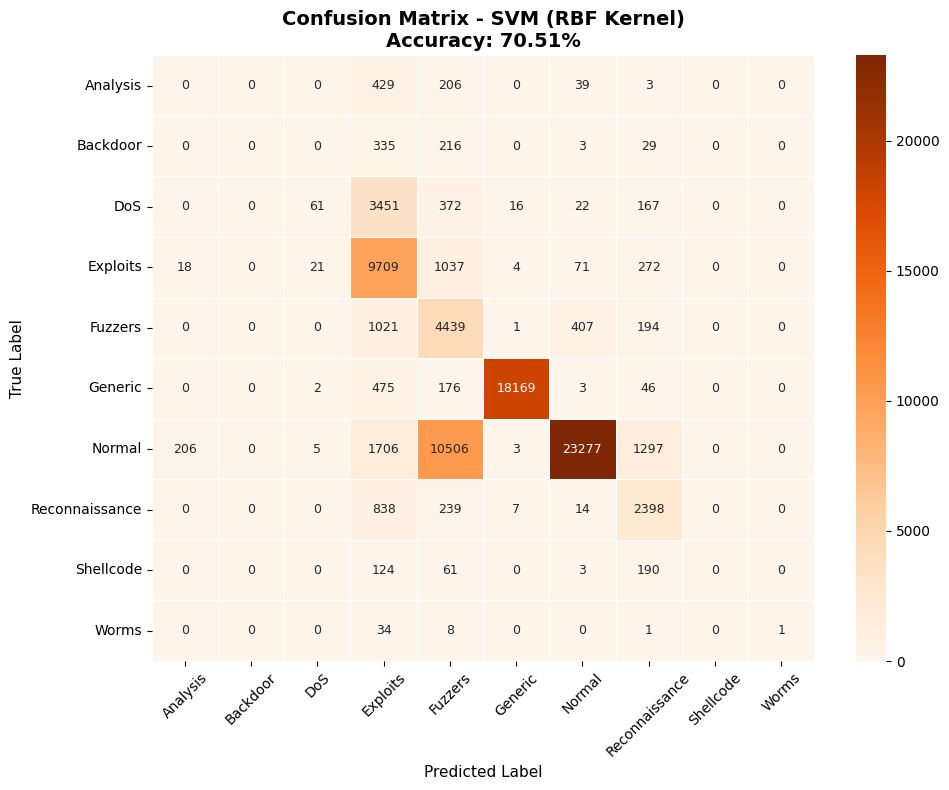

✅ confusion_matrix_svm.png berhasil disimpan


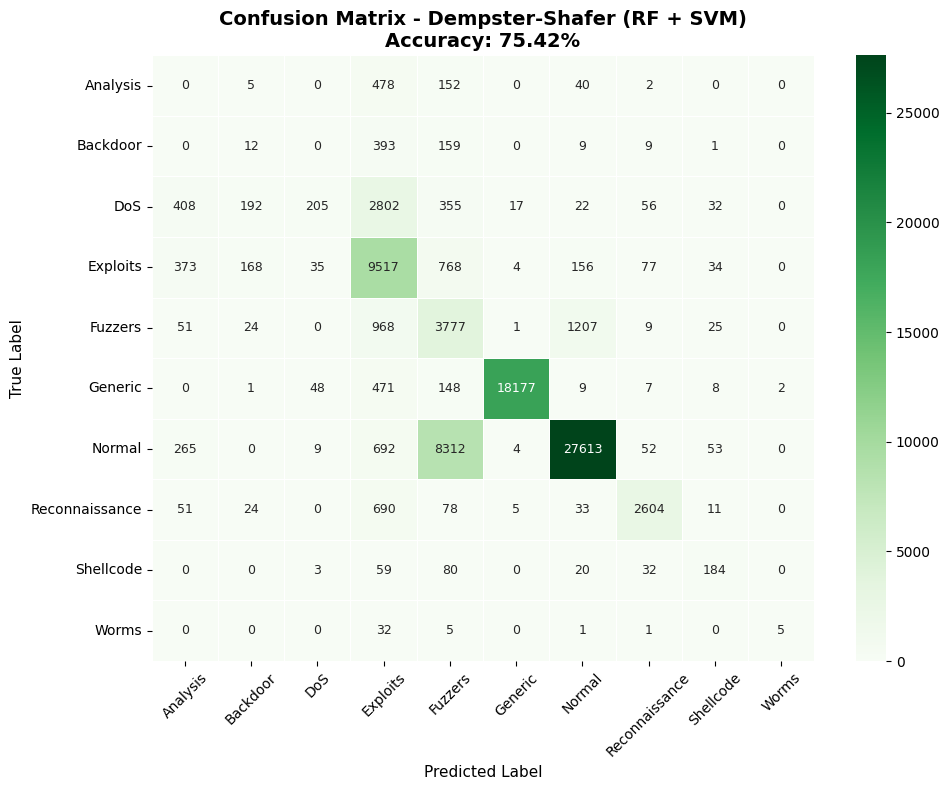

✅ confusion_matrix_dst.png berhasil disimpan


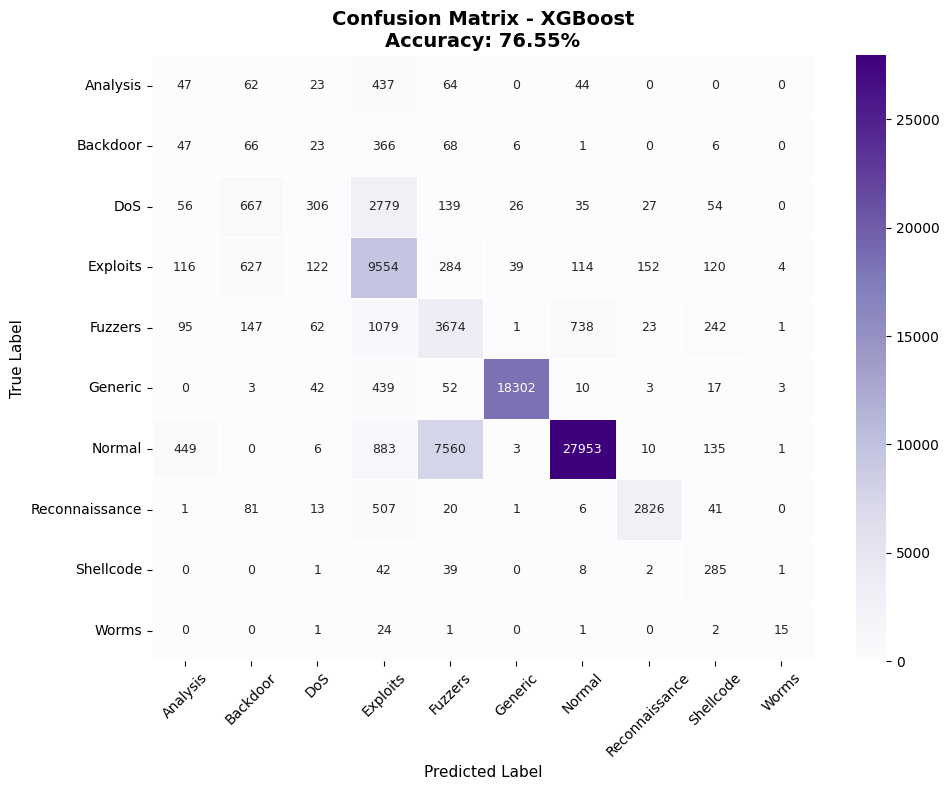

✅ confusion_matrix_xgb.png berhasil disimpan


In [10]:
from sklearn.metrics import confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

models_info = [
    (y_pred_rf,  'Random Forest',             'Blues',   'confusion_matrix_rf.png'),
    (y_pred_svm, 'SVM (RBF Kernel)',          'Oranges', 'confusion_matrix_svm.png'),
    (y_pred_dst, 'Dempster-Shafer (RF + SVM)','Greens',  'confusion_matrix_dst.png'),
    (y_pred_xgb, 'XGBoost',                   'Purples', 'confusion_matrix_xgb.png'),
]

for y_pred, title, cmap, filename in models_info:

    plt.figure(figsize=(10, 8))

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap=cmap,
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        linewidths=0.5,
        annot_kws={'size': 9}
    )

    acc = accuracy_score(y_test, y_pred)

    plt.title(
        f'Confusion Matrix - {title}\nAccuracy: {acc*100:.2f}%',
        fontsize=14,
        fontweight='bold'
    )

    plt.xlabel('Predicted Label', fontsize=11)
    plt.ylabel('True Label', fontsize=11)

    plt.xticks(rotation=45)
    plt.yticks(rotation=0)

    plt.tight_layout()

    plt.savefig(filename, dpi=300, bbox_inches='tight')

    plt.show()

    print(f'✅ {filename} berhasil disimpan')

---
## 10. Visualisasi — Perbandingan Metrik

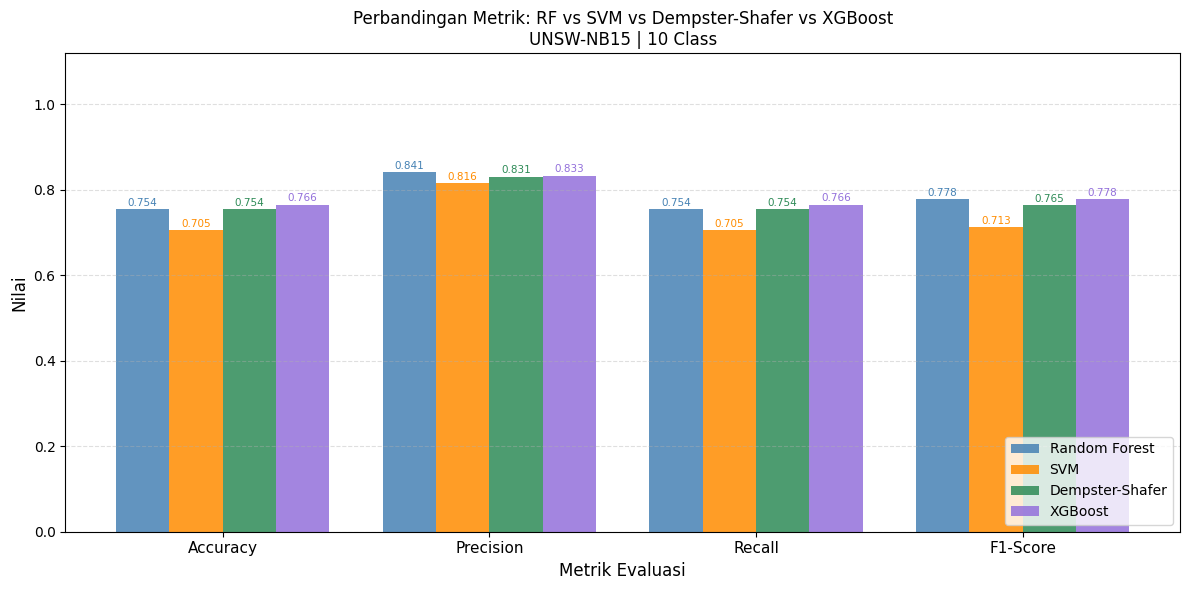

✅ Grafik tersimpan: comparison_10class.png


In [11]:
metrics    = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
rf_scores  = [rf_acc,  rf_prec,  rf_rec,  rf_f1]
svm_scores = [svm_acc, svm_prec, svm_rec, svm_f1]
dst_scores = [dst_acc, dst_prec, dst_rec, dst_f1]
xgb_scores = [xgb_acc, xgb_prec, xgb_rec, xgb_f1]

x      = np.arange(len(metrics))
width  = 0.2
colors = ['steelblue', 'darkorange', 'seagreen', 'mediumpurple']
labels = ['Random Forest', 'SVM', 'Dempster-Shafer', 'XGBoost']

fig, ax = plt.subplots(figsize=(12, 6))

for i, (scores, label, color) in enumerate(zip(
    [rf_scores, svm_scores, dst_scores, xgb_scores], labels, colors
)):
    bars = ax.bar(x + (i - 1.5) * width, scores, width,
                  label=label, color=color, alpha=0.85)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.003,
                f'{bar.get_height():.3f}',
                ha='center', va='bottom', fontsize=7.5, color=color)

ax.set_xlabel('Metrik Evaluasi', fontsize=12)
ax.set_ylabel('Nilai', fontsize=12)
ax.set_title('Perbandingan Metrik: RF vs SVM vs Dempster-Shafer vs XGBoost\nUNSW-NB15 | 10 Class', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 1.12)
ax.legend(fontsize=10, loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('comparison_10class.png', dpi=120, bbox_inches='tight')
plt.show()
print('✅ Grafik tersimpan: comparison_10class.png')

---
## 11. Kesimpulan

In [12]:
print('=' * 70)
print('                        KESIMPULAN')
print('=' * 70)
print(f'  Dataset       : UNSW-NB15')
print(f'  Jumlah kelas  : {N_CLASSES} kelas')
print(f'  Kelas         : {list(CLASS_NAMES)}')
print(f'  Data training : {len(df_train):,} records')
print(f'  Data testing  : {len(df_test):,} records')
print(f'  Rasio split   : ~68% : ~32%')
print('-' * 70)
print(f"  {'Metrik':<12} | {'RF':>8} | {'SVM':>8} | {'DST':>8} | {'XGB':>8} | Terbaik")
print('-' * 70)

for i, metric in enumerate(metric_names):
    vals  = [all_scores[m][i] for m in all_scores]
    best  = list(all_scores.keys())[np.argmax(vals)]
    print(f'  {metric:<12} | {vals[0]:>8.4f} | {vals[1]:>8.4f} | {vals[2]:>8.4f} | {vals[3]:>8.4f} | {best}')

print('=' * 70)

f1_all     = {m: all_scores[m][3] for m in all_scores}
best_model = max(f1_all, key=f1_all.get)
print(f'\n🏆 Model terbaik (F1-Score) : {best_model} ({f1_all[best_model]:.4f})')
print(f'\n📝 Catatan:')
print(f'   - Dempster-Shafer menggabungkan bukti dari RF dan SVM')
print(f'   - Rata-rata konflik (K) RF vs SVM : {np.mean(K_values):.4f}')
print(f'   - K mendekati 0 = RF & SVM sering setuju pada prediksi yang sama')
print(f'   - Waktu training: RF={rf_train_time:.2f}s | SVM={svm_train_time:.2f}s | XGB={xgb_train_time:.2f}s')

                        KESIMPULAN
  Dataset       : UNSW-NB15
  Jumlah kelas  : 10 kelas
  Kelas         : ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']
  Data training : 175,341 records
  Data testing  : 82,332 records
  Rasio split   : ~68% : ~32%
----------------------------------------------------------------------
  Metrik       |       RF |      SVM |      DST |      XGB | Terbaik
----------------------------------------------------------------------
  Accuracy     |   0.7543 |   0.7051 |   0.7542 |   0.7655 | XGBoost
  Precision    |   0.8411 |   0.8157 |   0.8309 |   0.8330 | Random Forest
  Recall       |   0.7543 |   0.7051 |   0.7542 |   0.7655 | XGBoost
  F1-Score     |   0.7780 |   0.7130 |   0.7647 |   0.7778 | Random Forest

🏆 Model terbaik (F1-Score) : Random Forest (0.7780)

📝 Catatan:
   - Dempster-Shafer menggabungkan bukti dari RF dan SVM
   - Rata-rata konflik (K) RF vs SVM : 0.3352
   - K mende